# Fashion GAN: Conditional GAN built from scratch

Generate new clothing images of a chosen category with a GAN trained on Fashion-MNIST.

1. How a GAN works
2. Generator + three discriminators: Vanilla GAN, cGAN, AC-GAN
3. Compare the discriminators
4. Train the final model
5. Input vs output

**Data:** Fashion-MNIST, 70,000 grayscale 28×28 images, 10 categories.
**Run:** Colab, *Runtime → Change runtime type → T4 GPU*, then *Run all* (about 25 min).

## How a GAN works

| | Generator (G) | Discriminator (D) |
|---|---|---|
| Input | noise z + category | image + category |
| Output | fake image | probability the image is real |
| Goal | fool D | catch fakes |

Each training step:
1. Train D: real images → 1, fake images → 0.
2. Train G: make D output 1 for fakes.

G never sees a real image. It learns only from D's gradients.

## 1. Setup

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.metrics import accuracy_score, confusion_matrix
import tensorflow as tf
import keras
from keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
OUT_DIR = "gan_outputs"
os.makedirs(OUT_DIR, exist_ok=True)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (enable it: Runtime → Change runtime type)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the data
Pixels are scaled to [-1, 1] to match the generator's `tanh` output.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train: (60000, 28, 28, 1)  test: (10000, 28, 28, 1)


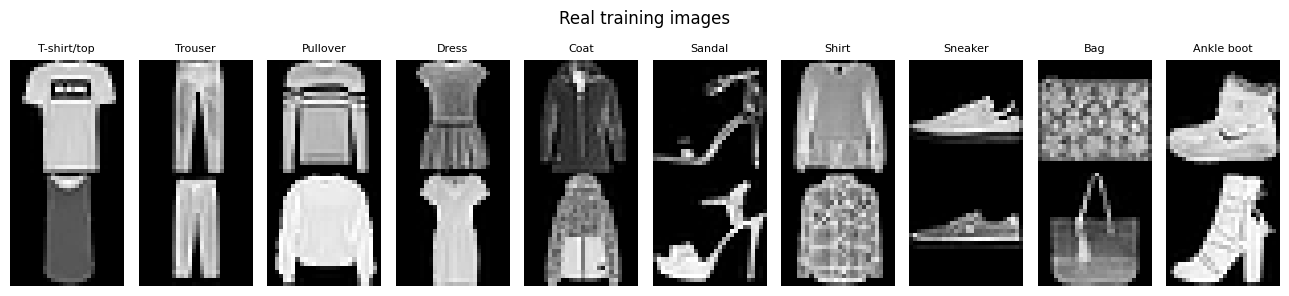

In [2]:
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
N_CLASSES = 10

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train = (x_train.astype("float32") / 127.5 - 1.0)[..., None]      # (60000, 28, 28, 1) in [-1, 1]
x_test = (x_test.astype("float32") / 127.5 - 1.0)[..., None]
print("train:", x_train.shape, " test:", x_test.shape)

def to_img(x):
    # [-1, 1] → [0, 1] for plotting
    return (np.squeeze(x) + 1) / 2

fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for c in range(N_CLASSES):
    for r in range(2):
        axes[r, c].imshow(to_img(x_train[np.where(y_train == c)[0][r]]), cmap="gray")
        axes[r, c].axis("off")
    axes[0, c].set_title(CLASS_NAMES[c], fontsize=8)
plt.suptitle("Real training images"); plt.tight_layout(); plt.show()

## 3. Generator
Noise (100) + label → 28×28 image.

* **Embedding:** turns the label into a learned vector.
* **Conv2DTranspose:** upsamples 7 → 14 → 28.
* **BatchNorm + LeakyReLU:** stable training.
* **tanh:** output in [-1, 1].

In [3]:
LATENT_DIM = 100

def build_generator():
    noise = keras.Input(shape=(LATENT_DIM,), name="noise")
    label = keras.Input(shape=(1,), dtype="int32", name="label")

    l = layers.Embedding(N_CLASSES, 50)(label)            # category → 50 learned numbers
    l = layers.Dense(7 * 7)(l)
    l = layers.Reshape((7, 7, 1))(l)

    n = layers.Dense(7 * 7 * 128)(noise)
    n = layers.LeakyReLU(0.2)(n)
    n = layers.Reshape((7, 7, 128))(n)

    x = layers.Concatenate()([n, l])                       # 7 × 7 × 129
    x = layers.Conv2DTranspose(128, 4, strides=2, padding="same")(x)   # 14 × 14
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Conv2DTranspose(64, 4, strides=2, padding="same")(x)    # 28 × 28
    x = layers.BatchNormalization()(x)
    x = layers.LeakyReLU(0.2)(x)
    image = layers.Conv2D(1, 7, padding="same", activation="tanh")(x)  # 28 × 28 × 1
    return keras.Model([noise, label], image, name="generator")

build_generator().summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ noise (InputLayer)  │ (None, 100)       │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ label (InputLayer)  │ (None, 1)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 6272)      │    633,472 │ noise[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 1, 50)     │        500 │ label[0][0]       │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu         │ (None, 6272)      │          0 │ dense_1[0][0]     │
│ (LeakyReLU)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 1, 49)     │      2,499 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 7, 7, 128) │          0 │ leaky_re_lu[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 7, 7, 1)   │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 7, 7, 129) │          0 │ reshape_1[0][0],  │
│ (Concatenate)       │                   │            │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 14, 14,    │    264,320 │ concatenate[0][0] │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 14, 14,    │        512 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_1       │ (None, 14, 14,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_1  │ (None, 28, 28,    │    131,136 │ leaky_re_lu_1[0]… │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 28, 28,    │        256 │ conv2d_transpose… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ leaky_re_lu_2       │ (None, 28, 28,    │          0 │ batch_normalizat… │
│ (LeakyReLU)         │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 28, 28, 1) │      3,137 │ leaky_re_lu_2[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,035,832 (3.95 MB)

 Trainable params: 1,035,448 (3.95 MB)

 Non-trainable params: 384 (1.50 KB)

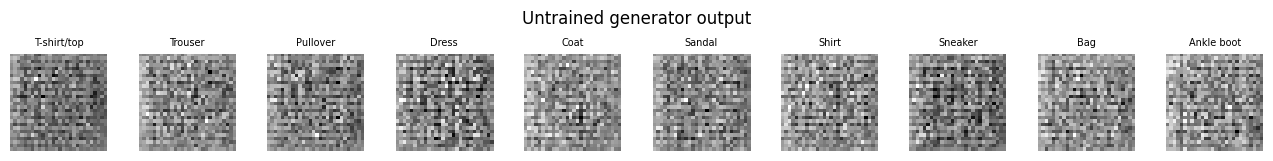

In [4]:
# Before training, the generator only produces noise:
g = build_generator()
fake = g([tf.random.normal([10, LATENT_DIM]), tf.constant(np.arange(10)[:, None])])
fig, axes = plt.subplots(1, 10, figsize=(13, 1.6))
for i in range(10):
    axes[i].imshow(to_img(fake[i]), cmap="gray"); axes[i].axis("off"); axes[i].set_title(CLASS_NAMES[i], fontsize=7)
plt.suptitle("Untrained generator output"); plt.tight_layout(); plt.show()

## 4. Three discriminators
Same CNN body for all: two stride-2 Conv2D layers (28 → 14 → 7), LeakyReLU, Dropout. Only the label handling differs.

| Discriminator | Label use | Output | Loss |
|---|---|---|---|
| Vanilla GAN | none | real/fake | BCE |
| cGAN | label map added as a 2nd image channel | real/fake | BCE |
| AC-GAN | predicts the label | real/fake + class | BCE + cross-entropy |

D outputs a logit. `sigmoid(logit)` is the probability "real".

In [5]:
def conv_base(x):
    x = layers.Conv2D(64, 4, strides=2, padding="same")(x)    # 14 × 14
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Conv2D(128, 4, strides=2, padding="same")(x)   # 7 × 7
    x = layers.LeakyReLU(0.2)(x)
    x = layers.Dropout(0.3)(x)
    return layers.Flatten()(x)

def build_discriminator(kind):
    image = keras.Input(shape=(28, 28, 1), name="image")
    label = keras.Input(shape=(1,), dtype="int32", name="label")

    if kind == "vanilla":
        real_fake = layers.Dense(1)(conv_base(image))
        return keras.Model(image, real_fake, name="D_vanilla")

    if kind == "cgan":
        l = layers.Embedding(N_CLASSES, 50)(label)
        l = layers.Dense(28 * 28)(l)
        l = layers.Reshape((28, 28, 1))(l)
        x = layers.Concatenate()([image, l])                   # 28 × 28 × 2
        real_fake = layers.Dense(1)(conv_base(x))
        return keras.Model([image, label], real_fake, name="D_cgan")

    if kind == "acgan":
        features = conv_base(image)
        real_fake = layers.Dense(1, name="real_fake")(features)
        category = layers.Dense(N_CLASSES, name="category")(features)
        return keras.Model(image, [real_fake, category], name="D_acgan")

DISCRIMINATORS = ["vanilla", "cgan", "acgan"]
for kind in DISCRIMINATORS:
    d = build_discriminator(kind)
    print(f"{d.name:10s} parameters: {d.count_params():,}")

D_vanilla  parameters: 138,561
D_cgan     parameters: 180,069
D_acgan    parameters: 201,291


## 5. Losses and training step
* **D loss:** BCE(D(real), 1) + BCE(D(fake), 0)
* **G loss:** BCE(D(fake), 1)
* **AC-GAN:** both also add a class loss.

`tf.GradientTape` updates only D in step 1 and only G in step 2. Adam, lr 0.0002, beta_1 0.5 (DCGAN settings).
Every run's models and settings are saved for the training log.

In [6]:
bce = keras.losses.BinaryCrossentropy(from_logits=True)
cce = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

LEARNING_RATE = 2e-4

def make_gan(kind):
    keras.utils.set_random_seed(SEED)
    G = build_generator()
    D = build_discriminator(kind)
    g_opt = keras.optimizers.Adam(LEARNING_RATE, beta_1=0.5)
    d_opt = keras.optimizers.Adam(LEARNING_RATE, beta_1=0.5)

    def run_D(images, labels):
        # Returns (real/fake logit, category logits or None)
        if kind == "vanilla":
            return D(images, training=True), None
        if kind == "cgan":
            return D([images, labels], training=True), None
        return D(images, training=True)                      # acgan → two outputs

    @tf.function
    def train_step(real_images, labels):
        batch = tf.shape(real_images)[0]
        noise = tf.random.normal([batch, LATENT_DIM])

        # ---- Step 1: train the discriminator
        with tf.GradientTape() as tape:
            fake_images = G([noise, labels], training=True)
            real_out, real_cls = run_D(real_images, labels)
            fake_out, fake_cls = run_D(fake_images, labels)
            d_loss = bce(tf.ones_like(real_out), real_out) + bce(tf.zeros_like(fake_out), fake_out)
            if kind == "acgan":
                d_loss += cce(labels, real_cls) + cce(labels, fake_cls)
        grads = tape.gradient(d_loss, D.trainable_variables)
        d_opt.apply_gradients(zip(grads, D.trainable_variables))

        # ---- Step 2: train the generator
        with tf.GradientTape() as tape:
            fake_images = G([noise, labels], training=True)
            fake_out, fake_cls = run_D(fake_images, labels)
            g_loss = bce(tf.ones_like(fake_out), fake_out)          # wants D to say "real"
            if kind == "acgan":
                g_loss += cce(labels, fake_cls)
        grads = tape.gradient(g_loss, G.trainable_variables)
        g_opt.apply_gradients(zip(grads, G.trainable_variables))
        return d_loss, g_loss

    return G, D, train_step

BATCH_SIZE = 128
dataset = (tf.data.Dataset.from_tensor_slices((x_train, y_train[:, None].astype("int32")))
           .shuffle(60000, seed=SEED).batch(BATCH_SIZE, drop_remainder=True).prefetch(tf.data.AUTOTUNE))

def train(train_step, epochs, on_epoch_end=None):
    history = []
    for epoch in range(1, epochs + 1):
        start = time.time()
        losses = [train_step(images, labels) for images, labels in dataset]
        d_loss, g_loss = np.mean([[float(d), float(g)] for d, g in losses], axis=0)
        history.append((d_loss, g_loss))
        print(f"epoch {epoch:2d} | D loss {d_loss:.3f} | G loss {g_loss:.3f} | {time.time() - start:.1f}s", flush=True)
        if on_epoch_end:
            on_epoch_end(epoch)
    return np.array(history)

# Save every run (models + one row in training_log.csv), including weaker ones.
LOG_FILE = os.path.join(OUT_DIR, "training_log.csv")

def save_run(run_name, kind, epochs, G, D, history, seconds, class_acc, note=""):
    folder = os.path.join("models", "runs", run_name)
    os.makedirs(folder, exist_ok=True)
    G.save(os.path.join(folder, "generator.keras"))
    D.save(os.path.join(folder, "discriminator.keras"))
    row = pd.DataFrame([{
        "run": run_name, "discriminator": kind, "epochs": epochs, "batch size": BATCH_SIZE,
        "learning rate": LEARNING_RATE, "latent dim": LATENT_DIM,
        "final D loss": round(history[-1, 0], 4), "final G loss": round(history[-1, 1], 4),
        "class accuracy": round(class_acc, 4), "time (s)": round(seconds, 1),
        "finished at": time.strftime("%Y-%m-%d %H:%M"), "note": note,
    }])
    row.to_csv(LOG_FILE, mode="a", header=not os.path.exists(LOG_FILE), index=False)
    print(f"saved run '{run_name}' → {folder}")

# The same 6 noise vectors for every category: rows = categories, columns = noise vectors
fixed_noise = tf.tile(tf.random.normal([6, LATENT_DIM], seed=SEED), [N_CLASSES, 1])
fixed_labels = tf.constant(np.repeat(np.arange(N_CLASSES), 6)[:, None], tf.int32)

def show_samples(G, title, path=None, show=True):
    images = G([fixed_noise, fixed_labels], training=False).numpy()
    fig, axes = plt.subplots(N_CLASSES, 6, figsize=(6, 10))
    for i, ax in enumerate(axes.ravel()):
        ax.imshow(to_img(images[i]), cmap="gray"); ax.set_xticks([]); ax.set_yticks([])
        if i % 6 == 0:
            ax.set_ylabel(CLASS_NAMES[i // 6], rotation=0, ha="right", va="center", fontsize=8)
    plt.suptitle(title); plt.tight_layout()
    if path:
        fig.savefig(path, dpi=80)
    plt.show() if show else plt.close(fig)

## 6. Judge classifier
A plain CNN trained on real images. **Class accuracy** = % of generated images the judge labels as the requested
category. Random guessing = 10%.

In [7]:
judge = keras.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(), layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dense(N_CLASSES, activation="softmax"),
], name="judge")
judge.compile("adam", "sparse_categorical_crossentropy", metrics=["accuracy"])
judge.fit(x_train, y_train, epochs=5, batch_size=128, validation_split=0.1, verbose=2)
print(f"Judge accuracy on real test images: {judge.evaluate(x_test, y_test, verbose=0)[1]:.3f}")

def generate(G, label, n):
    return G([tf.random.normal([n, LATENT_DIM]), tf.fill([n, 1], label)], training=False).numpy()

def class_accuracy(G, n_per_class=300):
    images = np.concatenate([generate(G, c, n_per_class) for c in range(N_CLASSES)])
    labels = np.repeat(np.arange(N_CLASSES), n_per_class)
    return accuracy_score(labels, judge.predict(images, verbose=0).argmax(1))

Epoch 1/5
422/422 - 15s - 36ms/step - accuracy: 0.8058 - loss: 0.5365 - val_accuracy: 0.8690 - val_loss: 0.3650
Epoch 2/5
422/422 - 2s - 5ms/step - accuracy: 0.8692 - loss: 0.3569 - val_accuracy: 0.8902 - val_loss: 0.3091
Epoch 3/5
422/422 - 2s - 5ms/step - accuracy: 0.8882 - loss: 0.3089 - val_accuracy: 0.8965 - val_loss: 0.2842
Epoch 4/5
422/422 - 2s - 5ms/step - accuracy: 0.8982 - loss: 0.2785 - val_accuracy: 0.9048 - val_loss: 0.2707
Epoch 5/5
422/422 - 2s - 5ms/step - accuracy: 0.9044 - loss: 0.2585 - val_accuracy: 0.9072 - val_loss: 0.2629
Judge accuracy on real test images: 0.903


## 7. Compare the discriminators
Same generator, data and 10 epochs. Only D changes. All three runs are saved.


===== vanilla =====
epoch  1 | D loss 1.376 | G loss 0.729 | 29.6s
epoch  2 | D loss 1.344 | G loss 0.741 | 21.4s
epoch  3 | D loss 1.320 | G loss 0.788 | 22.1s
epoch  4 | D loss 1.348 | G loss 0.753 | 22.7s
epoch  5 | D loss 1.347 | G loss 0.746 | 23.0s
epoch  6 | D loss 1.349 | G loss 0.747 | 22.9s
epoch  7 | D loss 1.350 | G loss 0.748 | 22.7s
epoch  8 | D loss 1.351 | G loss 0.752 | 22.8s
epoch  9 | D loss 1.354 | G loss 0.743 | 22.8s
epoch 10 | D loss 1.357 | G loss 0.743 | 22.9s
saved run 'compare_vanilla_10ep' → models/runs/compare_vanilla_10ep


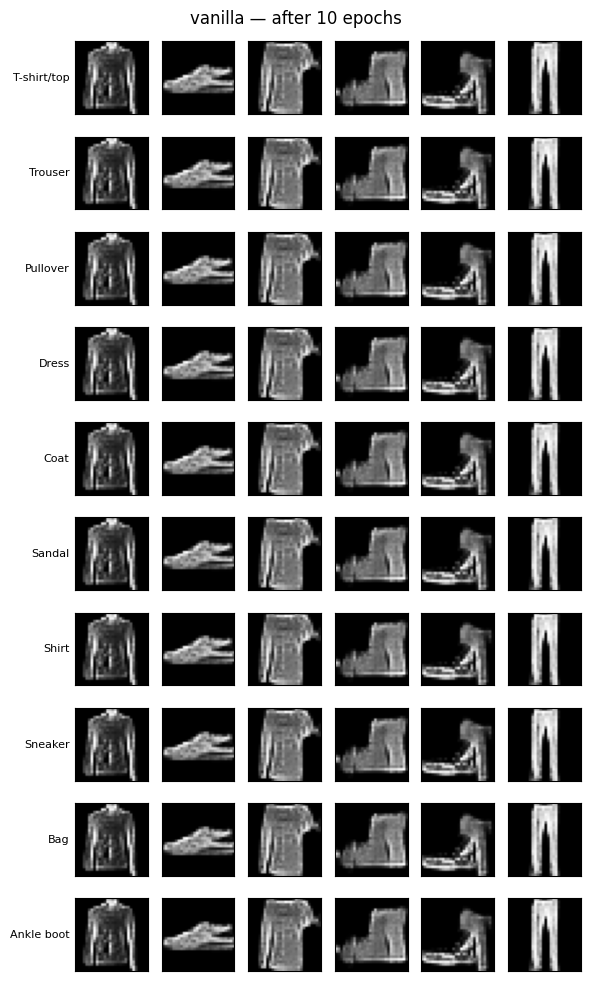


===== cgan =====
epoch  1 | D loss 1.358 | G loss 0.735 | 28.1s
epoch  2 | D loss 1.342 | G loss 0.747 | 23.8s
epoch  3 | D loss 1.288 | G loss 0.805 | 23.4s
epoch  4 | D loss 1.257 | G loss 0.876 | 23.4s
epoch  5 | D loss 1.254 | G loss 0.860 | 23.6s
epoch  6 | D loss 1.275 | G loss 0.810 | 23.5s
epoch  7 | D loss 1.278 | G loss 0.822 | 23.4s
epoch  8 | D loss 1.278 | G loss 0.820 | 23.4s
epoch  9 | D loss 1.286 | G loss 0.818 | 23.4s
epoch 10 | D loss 1.288 | G loss 0.817 | 23.5s
saved run 'compare_cgan_10ep' → models/runs/compare_cgan_10ep


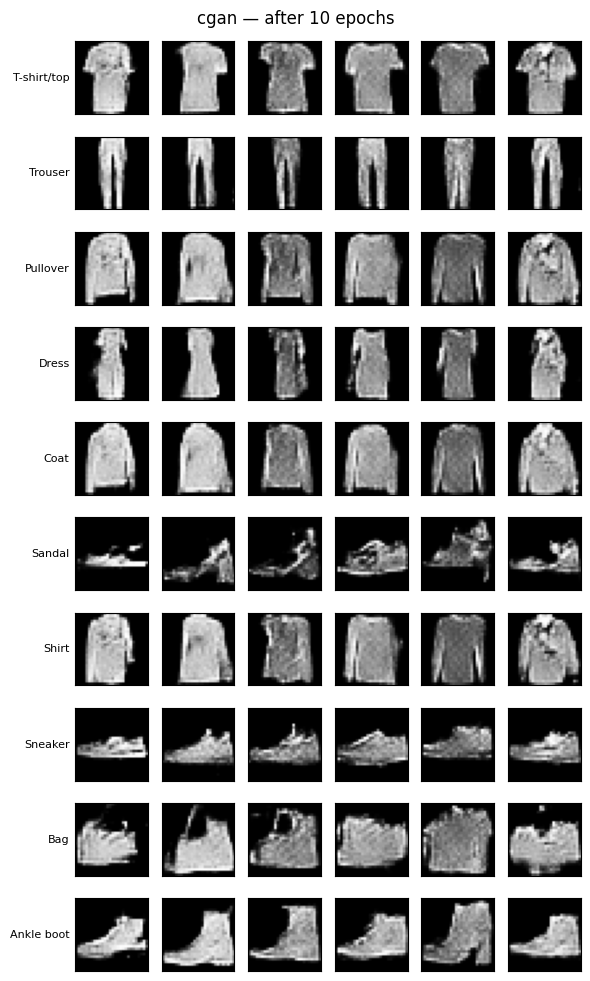


===== acgan =====
epoch  1 | D loss 2.460 | G loss 1.093 | 28.0s
epoch  2 | D loss 1.885 | G loss 0.799 | 23.5s
epoch  3 | D loss 1.755 | G loss 0.867 | 23.0s
epoch  4 | D loss 1.729 | G loss 0.857 | 23.0s
epoch  5 | D loss 1.729 | G loss 0.826 | 23.3s
epoch  6 | D loss 1.716 | G loss 0.810 | 23.2s
epoch  7 | D loss 1.700 | G loss 0.806 | 23.2s
epoch  8 | D loss 1.686 | G loss 0.803 | 23.1s
epoch  9 | D loss 1.683 | G loss 0.797 | 23.1s
epoch 10 | D loss 1.672 | G loss 0.794 | 23.2s
saved run 'compare_acgan_10ep' → models/runs/compare_acgan_10ep


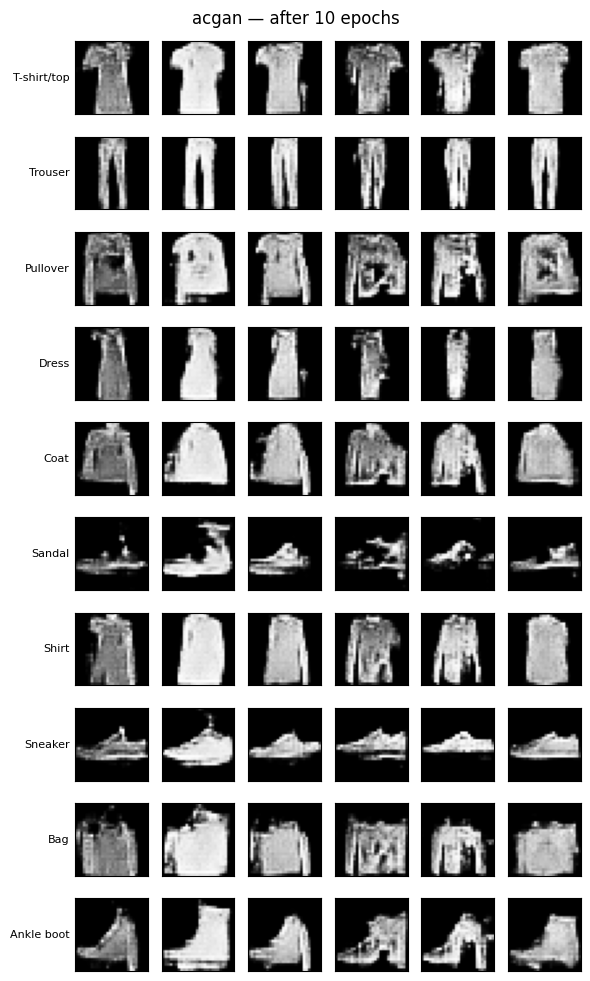

,class accuracy,final D loss,final G loss,training time (s)
vanilla,0.101,1.357,0.743,232.906
cgan,0.816,1.288,0.817,239.423
acgan,0.949,1.672,0.794,236.615


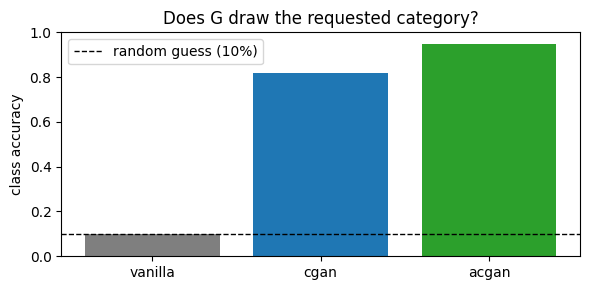

In [8]:
CMP_EPOCHS = 10
comparison = {}
for kind in DISCRIMINATORS:
    print(f"\n===== {kind} =====")
    G_k, D_k, step = make_gan(kind)
    start = time.time()
    hist = train(step, CMP_EPOCHS)
    seconds, acc = time.time() - start, class_accuracy(G_k)
    comparison[kind] = {"class accuracy": acc, "final D loss": hist[-1, 0], "final G loss": hist[-1, 1],
                        "training time (s)": seconds}
    save_run(f"compare_{kind}_{CMP_EPOCHS}ep", kind, CMP_EPOCHS, G_k, D_k, hist, seconds, acc,
             note="discriminator comparison")
    show_samples(G_k, f"{kind}: {CMP_EPOCHS} epochs", path=os.path.join(OUT_DIR, f"cmp_{kind}.png"))

comparison = pd.DataFrame(comparison).T
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(comparison.index, comparison["class accuracy"], color=["tab:gray", "tab:blue", "tab:green"])
ax.axhline(0.1, ls="--", c="k", lw=1, label="random guess (10%)")
ax.set_ylabel("class accuracy"); ax.set_ylim(0, 1); ax.legend(); ax.set_title("Does G draw the requested category?")
plt.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "discriminator_comparison.png"), dpi=100); plt.show()

**Result (10 epochs)**

| | Class accuracy | Why |
|---|---|---|
| Vanilla | 10.1% | D ignores the label, so G ignores it too |
| cGAN | 81.6% | D checks image + label |
| AC-GAN | 94.9% | G is rewarded for being classifiable, but variety is lower |

Final model: **cGAN**, the standard conditional GAN.

## 8. Train the final cGAN
30 epochs. One sample grid per epoch, combined into a GIF.

epoch  1 | D loss 1.357 | G loss 0.736 | 27.8s


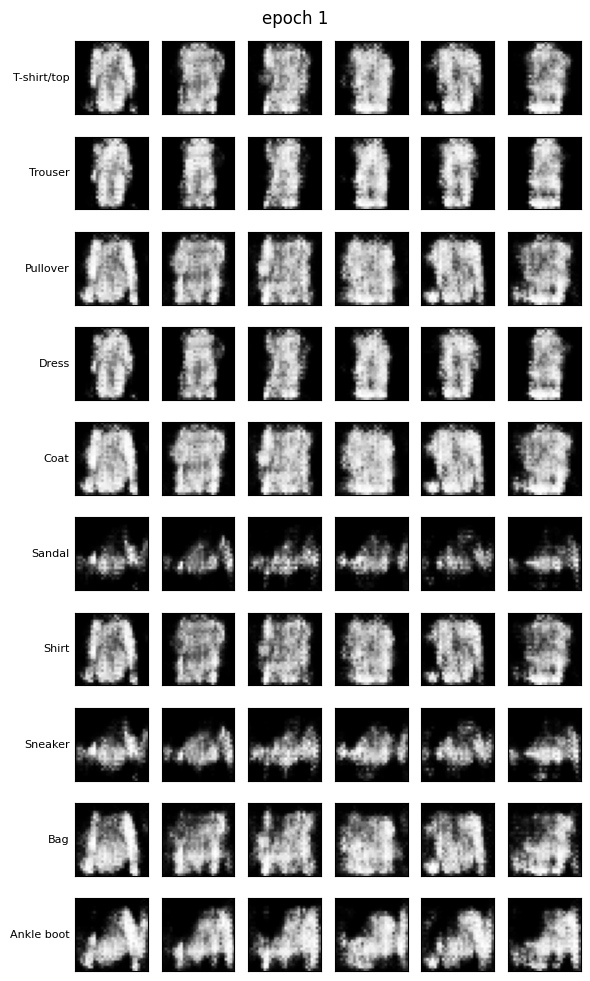

epoch  2 | D loss 1.345 | G loss 0.742 | 23.8s
epoch  3 | D loss 1.291 | G loss 0.810 | 23.5s
epoch  4 | D loss 1.255 | G loss 0.864 | 23.4s
epoch  5 | D loss 1.257 | G loss 0.825 | 23.6s
epoch  6 | D loss 1.273 | G loss 0.824 | 23.6s
epoch  7 | D loss 1.274 | G loss 0.833 | 23.6s
epoch  8 | D loss 1.276 | G loss 0.822 | 23.6s
epoch  9 | D loss 1.285 | G loss 0.830 | 23.5s
epoch 10 | D loss 1.287 | G loss 0.824 | 23.5s


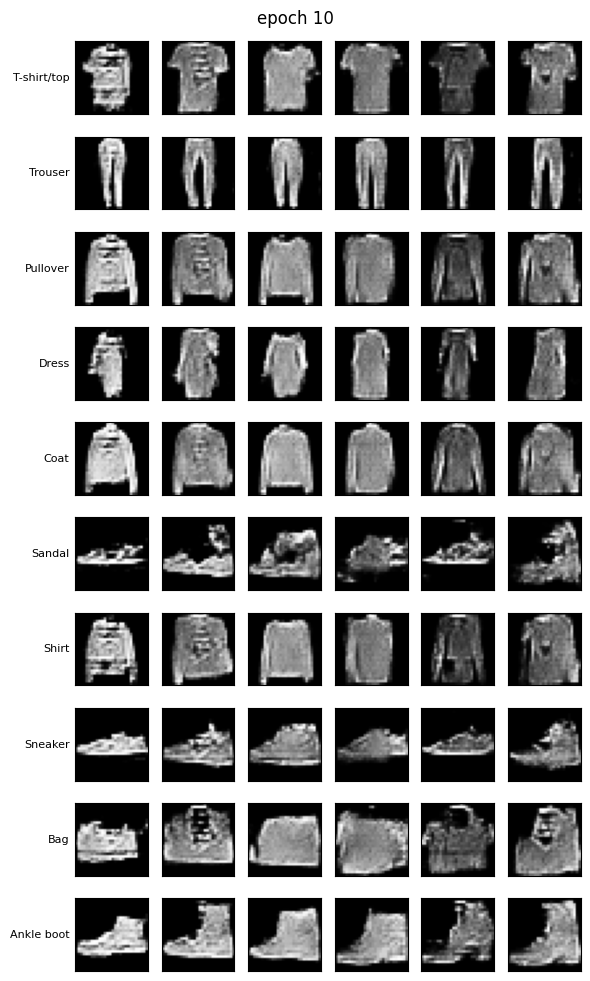

epoch 11 | D loss 1.287 | G loss 0.817 | 23.6s
epoch 12 | D loss 1.290 | G loss 0.820 | 23.6s
epoch 13 | D loss 1.290 | G loss 0.823 | 23.5s
epoch 14 | D loss 1.294 | G loss 0.818 | 23.5s
epoch 15 | D loss 1.297 | G loss 0.821 | 23.6s
epoch 16 | D loss 1.301 | G loss 0.815 | 23.6s
epoch 17 | D loss 1.302 | G loss 0.811 | 23.5s
epoch 18 | D loss 1.308 | G loss 0.816 | 23.6s
epoch 19 | D loss 1.307 | G loss 0.810 | 23.6s
epoch 20 | D loss 1.314 | G loss 0.811 | 23.5s
epoch 21 | D loss 1.311 | G loss 0.807 | 23.6s
epoch 22 | D loss 1.315 | G loss 0.809 | 23.6s
epoch 23 | D loss 1.317 | G loss 0.805 | 23.4s
epoch 24 | D loss 1.317 | G loss 0.802 | 23.5s
epoch 25 | D loss 1.322 | G loss 0.803 | 23.6s
epoch 26 | D loss 1.321 | G loss 0.800 | 23.6s
epoch 27 | D loss 1.323 | G loss 0.801 | 23.5s
epoch 28 | D loss 1.327 | G loss 0.796 | 23.4s
epoch 29 | D loss 1.327 | G loss 0.795 | 23.5s
epoch 30 | D loss 1.330 | G loss 0.796 | 23.5s


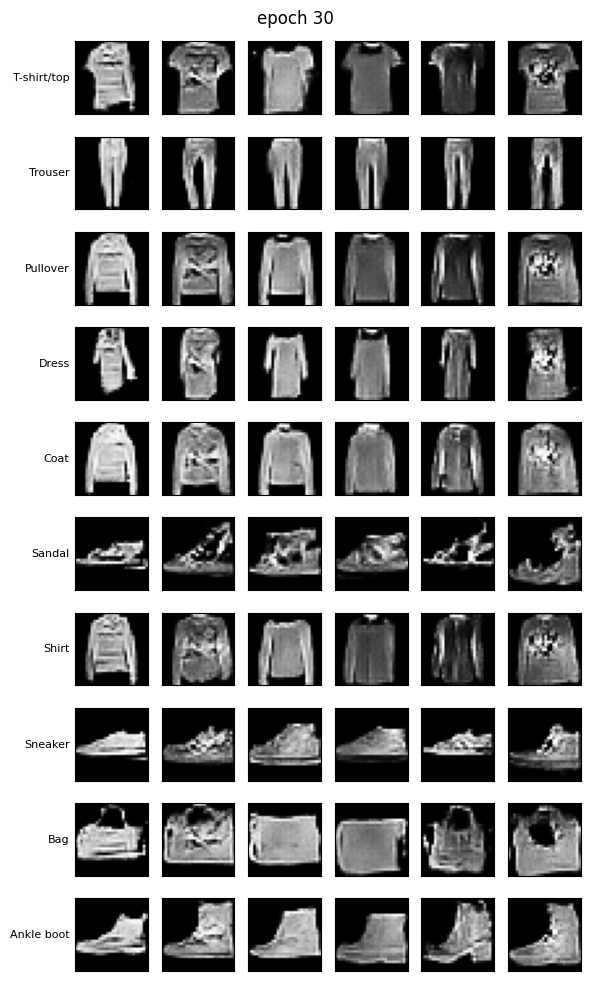

saved run 'final_cgan_30ep' → models/runs/final_cgan_30ep


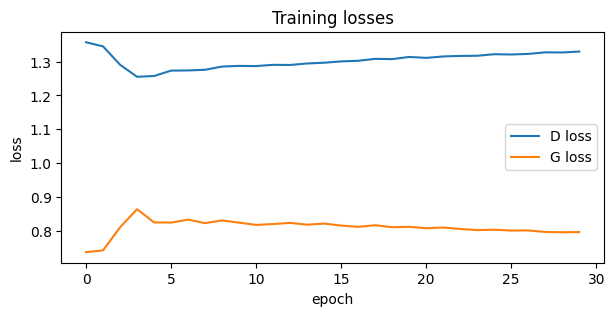

Final class accuracy: 0.893


,run,discriminator,epochs,batch size,learning rate,latent dim,final D loss,final G loss,class accuracy,time (s),finished at,note
0,compare_vanilla_10ep,vanilla,10,128,0.0002,100,1.3572,0.7430,0.1007,232.9,2026-10-29 05:05,discriminator comparison
1,compare_cgan_10ep,cgan,10,128,0.0002,100,1.2881,0.8175,0.8163,239.4,2026-10-29 05:09,discriminator comparison
2,compare_acgan_10ep,acgan,10,128,0.0002,100,1.6723,0.7943,0.9493,236.6,2026-10-29 05:13,discriminator comparison
3,final_cgan_30ep,cgan,30,128,0.0002,100,1.3296,0.7961,0.8930,758.3,2026-10-29 05:25,final model


In [9]:
EPOCHS = 30
G, D, train_step = make_gan("cgan")
start = time.time()
history = train(train_step, EPOCHS, on_epoch_end=lambda e: show_samples(
    G, f"epoch {e}", path=os.path.join(OUT_DIR, f"epoch_{e:02d}.png"), show=(e in (1, 10, EPOCHS))))
final_acc = class_accuracy(G)
save_run(f"final_cgan_{EPOCHS}ep", "cgan", EPOCHS, G, D, history, time.time() - start, final_acc, note="final model")

fig = plt.figure(figsize=(7, 3))
plt.plot(history[:, 0], label="D loss"); plt.plot(history[:, 1], label="G loss")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Training losses")
fig.savefig(os.path.join(OUT_DIR, "losses.png"), dpi=100); plt.show()

frames = [Image.open(os.path.join(OUT_DIR, f)) for f in sorted(os.listdir(OUT_DIR)) if f.startswith("epoch_")]
frames[0].save(os.path.join(OUT_DIR, "training.gif"), save_all=True, append_images=frames[1:], duration=300, loop=0)
print("Final class accuracy:", round(final_acc, 3))
display(pd.read_csv(LOG_FILE))                                # every run so far

GAN losses stay level instead of dropping to 0. If D loss reached 0, D would win and G would stop learning.

## 9. Input vs output
### 9.1 Inputs and output
Inputs: 100 noise values (shown as a 10×10 grid) + a label. Output: a 28×28 image.

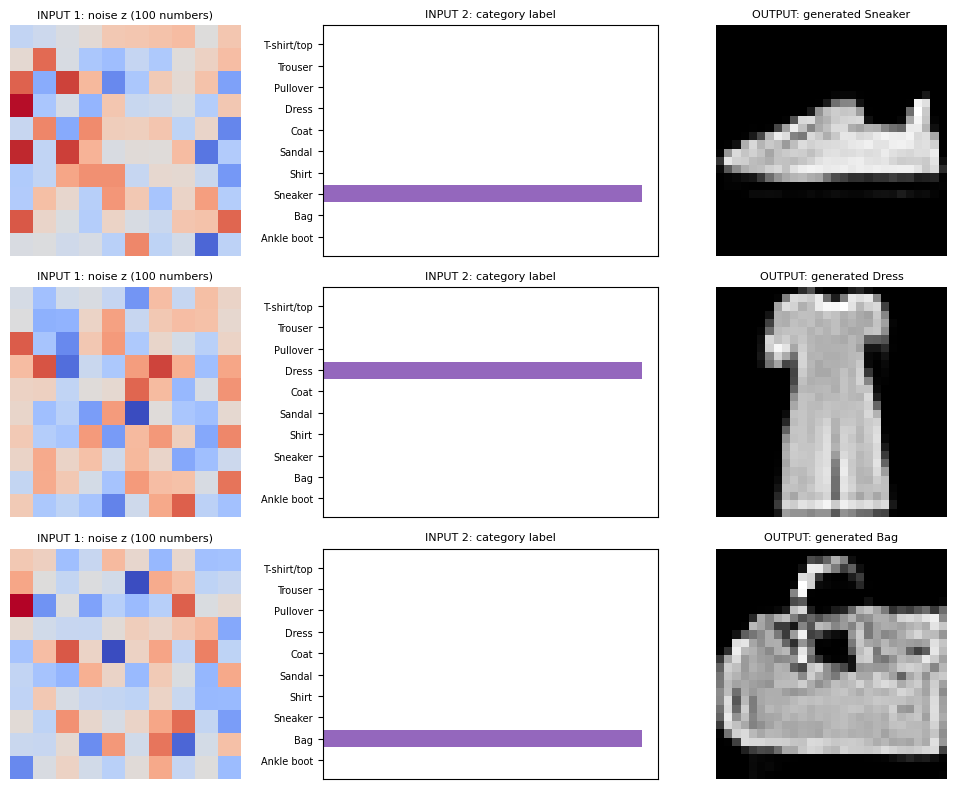

In [10]:
examples = [CLASS_NAMES.index(c) for c in ["Sneaker", "Dress", "Bag"]]
noise = tf.random.normal([3, LATENT_DIM], seed=7)
outputs = G([noise, tf.constant(np.array(examples)[:, None])], training=False).numpy()

fig, axes = plt.subplots(3, 3, figsize=(10, 8), gridspec_kw={"width_ratios": [1.2, 1.4, 1]})
for r, c in enumerate(examples):
    axes[r, 0].imshow(noise[r].numpy().reshape(10, 10), cmap="coolwarm", vmin=-2.5, vmax=2.5)
    axes[r, 0].set_title("INPUT 1: noise z (100 numbers)", fontsize=8); axes[r, 0].axis("off")
    onehot = np.eye(N_CLASSES)[c]
    axes[r, 1].barh(CLASS_NAMES, onehot, color=["tab:purple" if v else "lightgray" for v in onehot])
    axes[r, 1].invert_yaxis(); axes[r, 1].set_xticks([]); axes[r, 1].tick_params(labelsize=7)
    axes[r, 1].set_title("INPUT 2: category label", fontsize=8)
    axes[r, 2].imshow(to_img(outputs[r]), cmap="gray"); axes[r, 2].axis("off")
    axes[r, 2].set_title(f"OUTPUT: generated {CLASS_NAMES[c]}", fontsize=8)
plt.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "input_output.png"), dpi=100); plt.show()

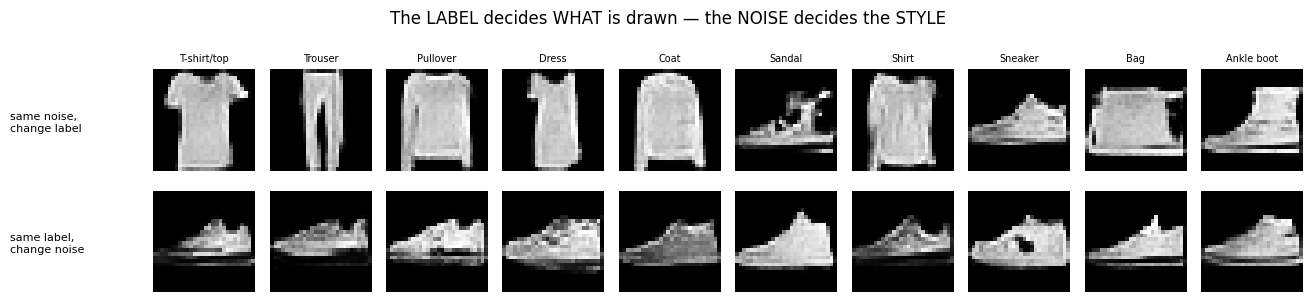

In [11]:
# Which input controls what?
fig, axes = plt.subplots(2, 10, figsize=(13, 3.2))
same_noise = tf.tile(tf.random.normal([1, LATENT_DIM], seed=11), [10, 1])
row1 = G([same_noise, tf.constant(np.arange(10)[:, None])], training=False).numpy()
row2 = generate(G, CLASS_NAMES.index("Sneaker"), 10)
for i in range(10):
    axes[0, i].imshow(to_img(row1[i]), cmap="gray"); axes[0, i].axis("off"); axes[0, i].set_title(CLASS_NAMES[i], fontsize=7)
    axes[1, i].imshow(to_img(row2[i]), cmap="gray"); axes[1, i].axis("off")
axes[0, 0].text(-40, 14, "same noise,\nchange label", fontsize=8, va="center")
axes[1, 0].text(-40, 14, "same label,\nchange noise", fontsize=8, va="center")
plt.suptitle("Label = WHAT is drawn, noise = STYLE")
plt.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "label_vs_noise.png"), dpi=100); plt.show()

### 9.2 Real vs generated averages
Bright pixels in the difference row = where the average shapes differ.

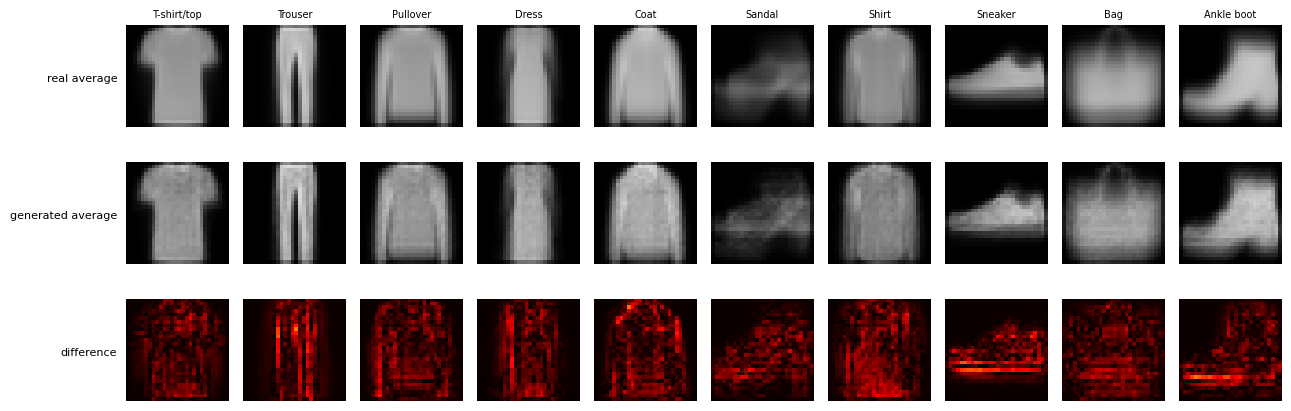

In [12]:
gen_images = np.concatenate([generate(G, c, 500) for c in range(N_CLASSES)])
gen_labels = np.repeat(np.arange(N_CLASSES), 500)

fig, axes = plt.subplots(3, 10, figsize=(13, 4.5))
for c in range(N_CLASSES):
    real_mean = x_train[y_train == c].mean(axis=0)
    gen_mean = gen_images[gen_labels == c].mean(axis=0)
    axes[0, c].imshow(to_img(real_mean), cmap="gray", vmin=0, vmax=1)
    axes[1, c].imshow(to_img(gen_mean), cmap="gray", vmin=0, vmax=1)
    axes[2, c].imshow(np.abs(np.squeeze(real_mean - gen_mean)) / 2, cmap="hot", vmin=0, vmax=0.3)
    axes[0, c].set_title(CLASS_NAMES[c], fontsize=7)
    for r in range(3):
        axes[r, c].axis("off")
for r, name in enumerate(["real average", "generated average", "difference"]):
    axes[r, 0].text(-3, 14, name, fontsize=8, ha="right", va="center")
plt.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "mean_difference.png"), dpi=100); plt.show()

### 9.3 Copying check
Each generated image next to its closest training image. A black difference would mean a copy.

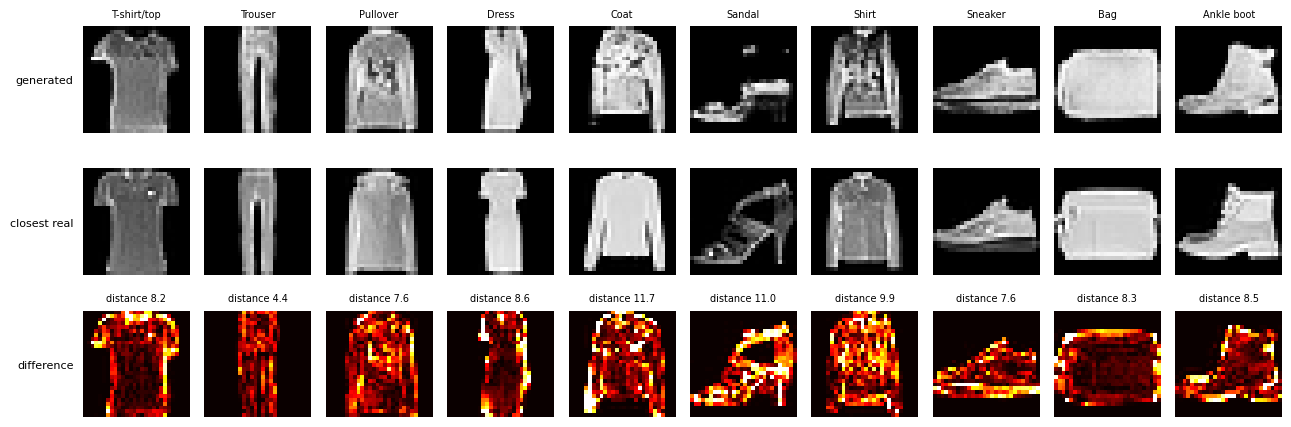

In [13]:
train_flat = x_train.reshape(len(x_train), -1)

def nearest_real(image):
    distances = np.sqrt(((train_flat - image.reshape(1, -1)) ** 2).sum(axis=1))
    return x_train[distances.argmin()], distances.min()

fig, axes = plt.subplots(3, 10, figsize=(13, 4.5))
for c in range(N_CLASSES):
    gen = gen_images[gen_labels == c][0]
    near, dist = nearest_real(gen)
    axes[0, c].imshow(to_img(gen), cmap="gray")
    axes[1, c].imshow(to_img(near), cmap="gray")
    axes[2, c].imshow(np.abs(np.squeeze(gen - near)) / 2, cmap="hot", vmin=0, vmax=0.5)
    axes[0, c].set_title(CLASS_NAMES[c], fontsize=7); axes[2, c].set_title(f"distance {dist:.1f}", fontsize=7)
    for r in range(3):
        axes[r, c].axis("off")
for r, name in enumerate(["generated", "closest real", "difference"]):
    axes[r, 0].text(-3, 14, name, fontsize=8, ha="right", va="center")
plt.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "nearest_difference.png"), dpi=100); plt.show()

### 9.4 Discriminator's view
Probability "real" for real, generated and random-noise images.

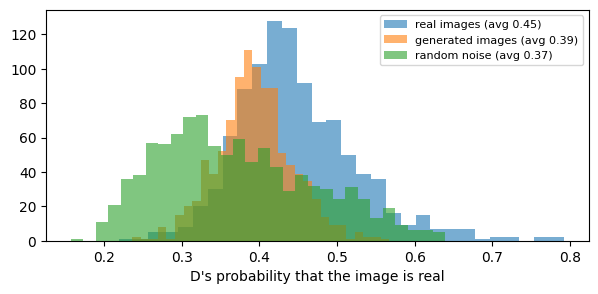

In [14]:
def d_probability(images, labels):
    return tf.sigmoid(D.predict([images, labels[:, None]], verbose=0)).numpy().ravel()

random_noise = np.random.uniform(-1, 1, (1000, 28, 28, 1)).astype("float32")
p_real = d_probability(x_test[:1000], y_test[:1000])
p_fake = d_probability(gen_images[::5], gen_labels[::5])
p_noise = d_probability(random_noise, np.random.randint(0, 10, 1000))

fig = plt.figure(figsize=(7, 3))
plt.hist(p_real, bins=30, alpha=0.6, label=f"real images (avg {p_real.mean():.2f})")
plt.hist(p_fake, bins=30, alpha=0.6, label=f"generated images (avg {p_fake.mean():.2f})")
plt.hist(p_noise, bins=30, alpha=0.6, label=f"random noise (avg {p_noise.mean():.2f})")
plt.xlabel("D's probability that the image is real"); plt.legend(fontsize=8)
fig.savefig(os.path.join(OUT_DIR, "discriminator_scores.png"), dpi=100, bbox_inches="tight"); plt.show()

Ideal: both real and generated near 0.5.

Result: real 0.45, generated 0.39, so G fools D most of the time. Noise scores 0.37 because D never saw noise in
training, so that score is not meaningful.

## 10. Judge accuracy per category

,judge accuracy on real images,judge accuracy on generated images
T-shirt/top,0.889,0.920
Trouser,0.973,0.994
Pullover,0.868,0.798
Dress,0.928,0.952
Coat,0.882,0.882
Sandal,0.985,0.982
Shirt,0.609,0.436
Sneaker,0.974,0.958
Bag,0.977,0.976
Ankle boot,0.941,0.944


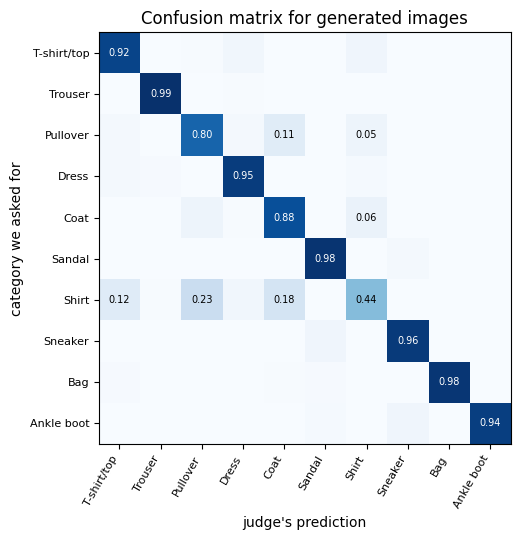

In [15]:
pred = judge.predict(gen_images, verbose=0).argmax(1)
real_pred = judge.predict(x_test, verbose=0).argmax(1)
fidelity = pd.DataFrame({
    "judge accuracy on real images": [accuracy_score(y_test[y_test == c], real_pred[y_test == c]) for c in range(N_CLASSES)],
    "judge accuracy on generated images": [accuracy_score(gen_labels[gen_labels == c], pred[gen_labels == c]) for c in range(N_CLASSES)],
}, index=CLASS_NAMES)
fidelity.loc["ALL"] = [accuracy_score(y_test, real_pred), accuracy_score(gen_labels, pred)]
display(fidelity.round(3))

cm = confusion_matrix(gen_labels, pred, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10), CLASS_NAMES, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(10), CLASS_NAMES, fontsize=8)
ax.set_xlabel("judge's prediction"); ax.set_ylabel("category we asked for")
for i in range(10):
    for j in range(10):
        if cm[i, j] >= 0.05:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if cm[i, j] > 0.5 else "black")
ax.set_title("Confusion matrix for generated images")
plt.tight_layout(); fig.savefig(os.path.join(OUT_DIR, "confusion_matrix.png"), dpi=100); plt.show()

Shirt, T-shirt, pullover and coat get mixed up most. The judge mixes them up on real images too.

## 11. Save the models

In [16]:
os.makedirs("models", exist_ok=True)
G.save("models/fashion_generator.keras")
D.save("models/fashion_discriminator.keras")
judge.save("models/fashion_judge.keras")
# 300 real images per category, used by the app to show "closest real image"
keep = np.concatenate([np.where(y_train == c)[0][:300] for c in range(N_CLASSES)])
np.savez_compressed("models/real_samples.npz", x=((x_train[keep, :, :, 0] + 1) * 127.5).round().astype(np.uint8),
                    y=y_train[keep])
comparison.to_csv(os.path.join(OUT_DIR, "discriminator_comparison.csv"))
fidelity.to_csv(os.path.join(OUT_DIR, "fidelity.csv"))
print("Saved.")

Saved.


## Summary
* A GAN trains a generator against a discriminator.
* A conditional GAN adds the label, so we choose what to generate.
* Vanilla 10.1%, cGAN 81.6%, AC-GAN 94.9% class accuracy at 10 epochs. Final cGAN (30 epochs): 89.3%.
* The label controls **what** is drawn, the noise controls the **style**. Outputs are new, not copies.

**Limitations:** 28×28 grayscale; similar tops get mixed up.

### Download results (Colab)

In [17]:
import shutil
os.makedirs("gan_results", exist_ok=True)
shutil.copytree(OUT_DIR, "gan_results/gan_outputs", dirs_exist_ok=True)
shutil.copytree("models", "gan_results/models", dirs_exist_ok=True)
shutil.make_archive("fashion_gan_results", "zip", "gan_results")
try:
    from google.colab import files
    files.download("fashion_gan_results.zip")
except ImportError:
    print("Saved fashion_gan_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>